In [ ]:
import numpy as np

# ---- 1. Synthetic dataset ----
np.random.seed(42)
X = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float)
y = 3.5 * X + 2 + np.random.randn(8) * 0.5   # y = 3.5x + 2 + noise

n = len(X)

def compute_cost(X, y, w, b):
    predictions = w * X + b
    errors = predictions - y
    return (1 / (2 * n)) * np.sum(errors ** 2)

def batch_gradient_descent(X, y, lr=0.01, epochs=1000):
    w, b = 0.0, 0.0
    cost_history = []

    for epoch in range(epochs):
        predictions = w * X + b
        errors = predictions - y

        # Gradients computed over the FULL dataset
        dw = (1 / n) * np.sum(errors * X)
        db = (1 / n) * np.sum(errors)

        # Parameter update
        w -= lr * dw
        b -= lr * db

        cost_history.append(compute_cost(X, y, w, b))

    return w, b, cost_history

w, b, history = batch_gradient_descent(X, y, lr=0.01, epochs=1000)

print(f"Learned weight (w): {w:.4f}")
print(f"Learned bias   (b): {b:.4f}")
print(f"Final cost         : {history[-1]:.6f}")


Learned weight (w): 3.5709
Learned bias   (b): 1.9176
Final cost         : 0.059371


In [2]:
import matplotlib.pyplot as plt

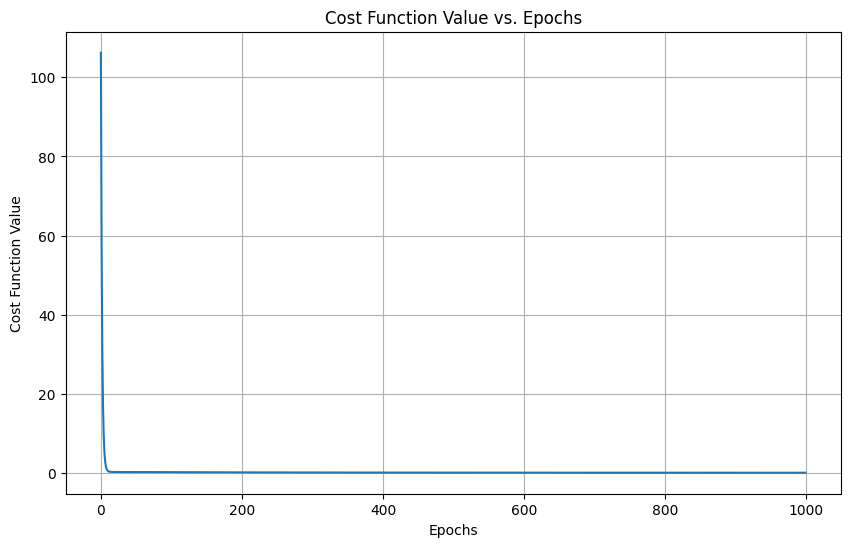

In [3]:
plt.figure(figsize=(10, 6))
plt.plot(history)
plt.xlabel('Epochs')
plt.ylabel('Cost Function Value')
plt.title('Cost Function Value vs. Epochs')
plt.grid(True)
plt.show()

## Multivariate Linear Regression with Batch Gradient Descent

Now, let's extend the Batch Gradient Descent implementation to handle multiple input features (multivariate linear regression).

In [4]:
import numpy as np

# --- 1. Generate a new synthetic dataset with multiple features ---
np.random.seed(42)

# Number of features
num_features = 3
# Number of samples
n_samples = 100

# Generate random input features
X_multi = np.random.rand(n_samples, num_features) * 10

# Define true weights and bias for the synthetic data
true_weights = np.array([3.0, -1.5, 2.5])
true_bias = 5.0

# Generate target variable with noise
y_multi = X_multi @ true_weights + true_bias + np.random.randn(n_samples) * 2

print(f"Shape of X_multi: {X_multi.shape}")
print(f"Shape of y_multi: {y_multi.shape}")

Shape of X_multi: (100, 3)
Shape of y_multi: (100,)


### Updated `compute_cost` for Multivariate Regression

The cost function remains the same in principle (mean squared error), but predictions now involve a dot product of the feature matrix `X` and the weight vector `w`.

In [5]:
def compute_cost_multi(X, y, w, b):
    # Number of samples
    n_samples = len(y)
    # Predictions using dot product for multiple features
    predictions = X @ w + b
    errors = predictions - y
    return (1 / (2 * n_samples)) * np.sum(errors ** 2)

### Updated `batch_gradient_descent` for Multivariate Regression

Here, the main change is that `w` is now a vector, and its update involves multiplying the errors by each corresponding feature in `X`.

In [6]:
def batch_gradient_descent_multi(X, y, lr=0.01, epochs=1000):
    n_samples, num_features = X.shape
    # Initialize weights as a vector of zeros
    w = np.zeros(num_features)
    b = 0.0
    cost_history = []

    for epoch in range(epochs):
        predictions = X @ w + b
        errors = predictions - y

        # Gradients computed over the FULL dataset
        # dw is now a vector of gradients, one for each feature
        dw = (1 / n_samples) * (X.T @ errors) # X.T @ errors performs the sum for each feature
        db = (1 / n_samples) * np.sum(errors)

        # Parameter update (vectorized for w)
        w -= lr * dw
        b -= lr * db

        cost_history.append(compute_cost_multi(X, y, w, b))

    return w, b, cost_history

### Run Multivariate Batch Gradient Descent and Display Results

In [7]:
w_multi, b_multi, history_multi = batch_gradient_descent_multi(X_multi, y_multi, lr=0.01, epochs=1000)

print(f"Learned weights (w): {w_multi}")
print(f"Learned bias   (b): {b_multi:.4f}")
print(f"Final cost         : {history_multi[-1]:.6f}")

Learned weights (w): [ 3.15101574 -1.45219751  2.71689637]
Learned bias   (b): 2.9460
Final cost         : 1.957974


### Plotting the Cost Function for Multivariate Regression

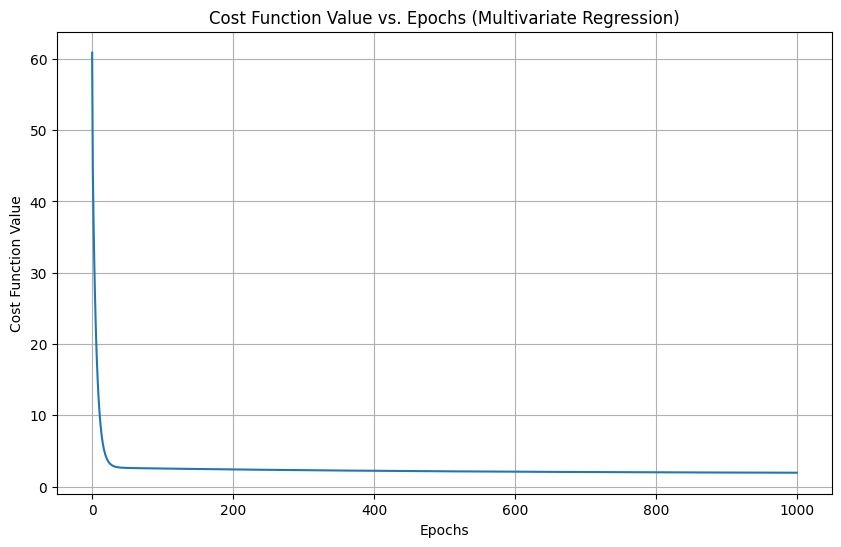

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(history_multi)
plt.xlabel('Epochs')
plt.ylabel('Cost Function Value')
plt.title('Cost Function Value vs. Epochs (Multivariate Regression)')
plt.grid(True)
plt.show()